In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [120]:
# 1. Load the actual dataset
ages = np.load("eICU_age.npy", allow_pickle=False)
print(ages)
print(ages.dtype.names)

[(87,) (87,) (76,) ... (41,) (72,) (50,)]
('age',)


In [121]:
# 2. Inspect the array
print("Shape:", ages.shape)
print("Data type:", ages.dtype)
print("Total elements:", ages.size)

Shape: (2520,)
Data type: [('age', 'i1')]
Total elements: 2520


In [122]:
# 3. Extract patient ages from the structured array
#ages = np.load("eICU_age.npy", allow_pickle=False)

# Extract the 'age' field
ages = ages["age"]

# Convert to a regular numeric array
ages = ages.astype(np.float64).reshape(-1)

print("Shape:", ages.shape)
print("Data type:", ages.dtype)
print("First 10 ages:", ages[:10])

Shape: (2520,)
Data type: float64
First 10 ages: [87. 87. 76. 34. 61. 55. 55. 60. 28. 34.]


In [123]:
# 4. Check invalid and missing values
print("Missing/non-numeric:", np.isnan(ages).sum())
print("Finite values:", np.isfinite(ages).sum())

Missing/non-numeric: 0
Finite values: 2520


Minimum: 15.0
Maximum: 90.0
Mean: 63.28452380952381
Median: 66.0
Std deviation: 17.721668608381833
Percentiles: [28. 53. 66. 77. 89.]


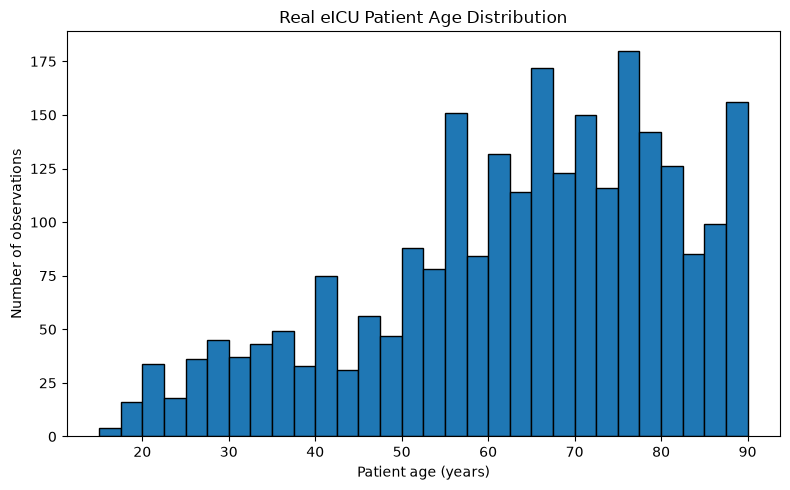

In [124]:
# 5. Keep finite observations for initial exploration
valid_ages = ages[np.isfinite(ages)]

if len(valid_ages) == 0:
    raise ValueError("No valid numeric ages found.")

# 6. Descriptive statistics
print("Minimum:", np.min(valid_ages))
print("Maximum:", np.max(valid_ages))
print("Mean:", np.mean(valid_ages))
print("Median:", np.median(valid_ages))
print("Std deviation:", np.std(valid_ages))
print("Percentiles:",
      np.percentile(valid_ages, [5, 25, 50, 75, 95]))

# 7. Visualize the actual age distribution
plt.figure(figsize=(8, 5))
plt.hist(valid_ages, bins=30, edgecolor="black")
plt.xlabel("Patient age (years)")
plt.ylabel("Number of observations")
plt.title("Real eICU Patient Age Distribution")
plt.tight_layout()
plt.show()

In [125]:
# Check age range and frequency
print("Minimum age:", valid_ages.min())
print("Maximum age:", valid_ages.max())

unique, counts = np.unique(valid_ages, return_counts=True)

print("Largest age values and their frequencies:")
for age, count in zip(unique[-10:], counts[-10:]):
    print(f"Age {age:.0f}: {count} patients")

Minimum age: 15.0
Maximum age: 90.0
Largest age values and their frequencies:
Age 81: 34 patients
Age 82: 54 patients
Age 83: 49 patients
Age 84: 36 patients
Age 85: 30 patients
Age 86: 26 patients
Age 87: 43 patients
Age 88: 25 patients
Age 89: 127 patients
Age 90: 4 patients


Original age range: 15.0 to 90.0
Normalized range: -1.0 to 1.0


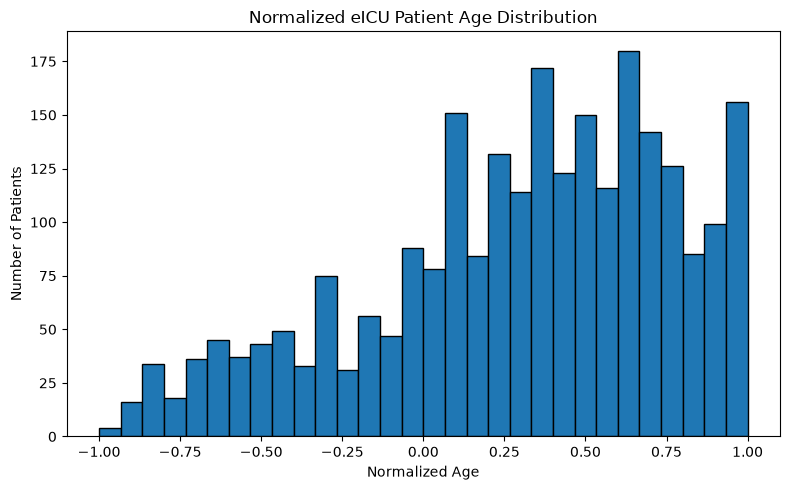

In [126]:
# 8. Normalize ages to [-1, 1]

age_min = valid_ages.min()
age_max = valid_ages.max()

normalized_ages = (
    2 * (valid_ages - age_min) / (age_max - age_min)
) - 1

print("Original age range:", age_min, "to", age_max)
print("Normalized range:",
      normalized_ages.min(),
      "to",
      normalized_ages.max())

# Visualize normalized ages
plt.figure(figsize=(8, 5))
plt.hist(normalized_ages, bins=30, edgecolor="black")
plt.xlabel("Normalized Age")
plt.ylabel("Number of Patients")
plt.title("Normalized eICU Patient Age Distribution")
plt.tight_layout()
plt.show()

In [127]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [128]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch installed successfully!")

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
PyTorch installed successfully!
CUDA available: False


In [129]:
#import torch
#import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)

# Convert normalized ages into a tensor
age_tensor = torch.tensor(
    normalized_ages.reshape(-1, 1),
    dtype=torch.float32
)

# Create dataset and dataloader
train_dataset = TensorDataset(age_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

print("Tensor shape:", age_tensor.shape)
print("Number of batches:", len(train_loader))

Tensor shape: torch.Size([2520, 1])
Number of batches: 20


In [130]:
#import torch
import torch.nn as nn

# Use CPU or GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Random noise dimension
latent_dim = 16

# Generator: random noise -> synthetic patient age
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


# Discriminator: patient age -> real/fake score
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(1, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)


# Initialize both models
generator = Generator().to(device)
discriminator = Discriminator().to(device)

print("Using device:", device)
print("\nGenerator:")
print(generator)
print("\nDiscriminator:")
print(discriminator)

Using device: cpu

Generator:
Generator(
  (model): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=64, out_features=1, bias=True)
    (5): Tanh()
  )
)

Discriminator:
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [131]:
# Binary cross-entropy loss for GAN training
criterion = nn.BCEWithLogitsLoss()

# Generator optimizer
optimizer_G = torch.optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# Discriminator optimizer
optimizer_D = torch.optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers initialized!")

Loss function and optimizers initialized!


In [132]:
# Test generator with 5 random samples
z = torch.randn(5, latent_dim).to(device)

fake_ages = generator(z)

print("Generator output shape:", fake_ages.shape)
print("Generated normalized ages:")
print(fake_ages.detach().cpu().numpy())

# Test discriminator
scores = discriminator(fake_ages)

print("\nDiscriminator output shape:", scores.shape)

Generator output shape: torch.Size([5, 1])
Generated normalized ages:
[[0.16774839]
 [0.10320851]
 [0.07029335]
 [0.17853352]
 [0.1319391 ]]

Discriminator output shape: torch.Size([5, 1])


In [133]:
# GAN training configuration
num_epochs = 300

g_losses = []
d_losses = []

# Store generated samples during training
generated_history = {}

# Fixed noise helps us compare progress across epochs
fixed_noise = torch.randn(1000, latent_dim, device=device)

for epoch in range(num_epochs):

    total_g_loss = 0.0
    total_d_loss = 0.0

    for (real_ages,) in train_loader:

        real_ages = real_ages.to(device)
        batch_size = real_ages.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # ---------------------------------
        # 1. Train Discriminator
        # ---------------------------------
        optimizer_D.zero_grad()

        # Generate synthetic ages
        z = torch.randn(batch_size, latent_dim, device=device)
        fake_ages = generator(z)

        # Discriminator loss on real ages
        real_outputs = discriminator(real_ages)
        d_loss_real = criterion(real_outputs, real_labels)

        # Discriminator loss on fake ages
        fake_outputs = discriminator(fake_ages.detach())
        d_loss_fake = criterion(fake_outputs, fake_labels)

        # Total discriminator loss
        d_loss = (d_loss_real + d_loss_fake) / 2

        d_loss.backward()
        optimizer_D.step()

        # ---------------------------------
        # 2. Train Generator
        # ---------------------------------
        optimizer_G.zero_grad()

        z = torch.randn(batch_size, latent_dim, device=device)
        generated_ages = generator(z)

        # Generator tries to fool discriminator
        outputs = discriminator(generated_ages)
        g_loss = criterion(outputs, real_labels)

        g_loss.backward()
        optimizer_G.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    # Average losses across batches
    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    d_losses.append(avg_d_loss)
    g_losses.append(avg_g_loss)

    # Save samples at selected epochs
    if (epoch + 1) in [1, 25, 50, 100, 200, 300]:
        generator.eval()
        with torch.no_grad():
            samples = generator(fixed_noise).cpu().numpy().flatten()
            generated_history[epoch + 1] = samples.copy()
        generator.train()

    # Display training progress
    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"D Loss: {avg_d_loss:.4f} "
            f"G Loss: {avg_g_loss:.4f}"
        )

print("GAN training completed!")

Epoch [25/300] D Loss: 0.6886 G Loss: 0.6950
Epoch [50/300] D Loss: 0.6960 G Loss: 0.6862
Epoch [75/300] D Loss: 0.6968 G Loss: 0.6944
Epoch [100/300] D Loss: 0.6929 G Loss: 0.6875
Epoch [125/300] D Loss: 0.6933 G Loss: 0.6951
Epoch [150/300] D Loss: 0.6923 G Loss: 0.6928
Epoch [175/300] D Loss: 0.6919 G Loss: 0.6955
Epoch [200/300] D Loss: 0.6925 G Loss: 0.6882
Epoch [225/300] D Loss: 0.6941 G Loss: 0.6886
Epoch [250/300] D Loss: 0.6947 G Loss: 0.6915
Epoch [275/300] D Loss: 0.6924 G Loss: 0.6981
Epoch [300/300] D Loss: 0.6927 G Loss: 0.6978
GAN training completed!


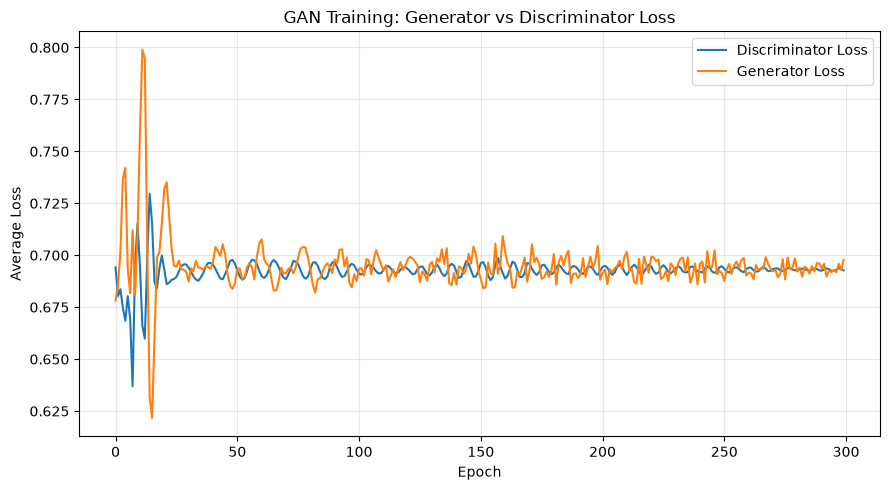

In [134]:
# Training loss Visualization
#import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(d_losses, label="Discriminator Loss")
plt.plot(g_losses, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("GAN Training: Generator vs Discriminator Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

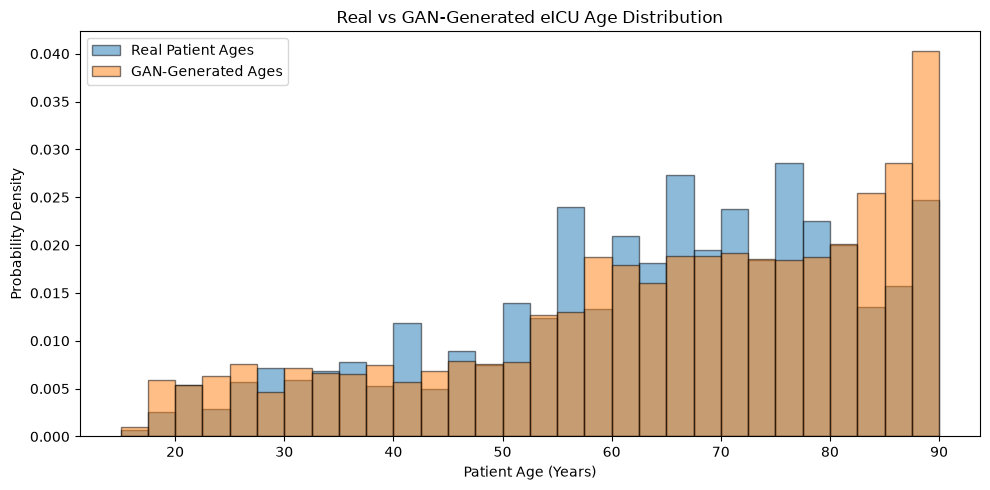

In [135]:
# Generate synthetic samples
generator.eval()

with torch.no_grad():
    z = torch.randn(
        len(valid_ages),
        latent_dim,
        device=device
    )
    fake_normalized = generator(z).cpu().numpy().flatten()

# Convert normalized values back to ages
generated_ages = (
    (fake_normalized + 1) / 2
) * (age_max - age_min) + age_min

# Use identical bins for fair comparison
bins = np.linspace(age_min, age_max, 31)

plt.figure(figsize=(10, 5))

plt.hist(
    valid_ages,
    bins=bins,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="Real Patient Ages"
)

plt.hist(
    generated_ages,
    bins=bins,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="GAN-Generated Ages"
)

plt.xlabel("Patient Age (Years)")
plt.ylabel("Probability Density")
plt.title("Real vs GAN-Generated eICU Age Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [136]:
# GAN quantitative Evaluation
from scipy.stats import wasserstein_distance, ks_2samp

print("Real mean:", np.mean(valid_ages))
print("Generated mean:", np.mean(generated_ages))

print("Real std:", np.std(valid_ages))
print("Generated std:", np.std(generated_ages))

wd = wasserstein_distance(valid_ages, generated_ages)
ks_stat, ks_pvalue = ks_2samp(valid_ages, generated_ages)

print("Wasserstein distance:", wd)
print("KS statistic:", ks_stat)
print("KS p-value:", ks_pvalue)

Real mean: 63.28452380952381
Generated mean: 64.99513060741481
Real std: 17.721668608381833
Generated std: 19.610432573335387
Wasserstein distance: 2.5364377405671843
KS statistic: 0.12023809523809524
KS p-value: 2.776941461793598e-16


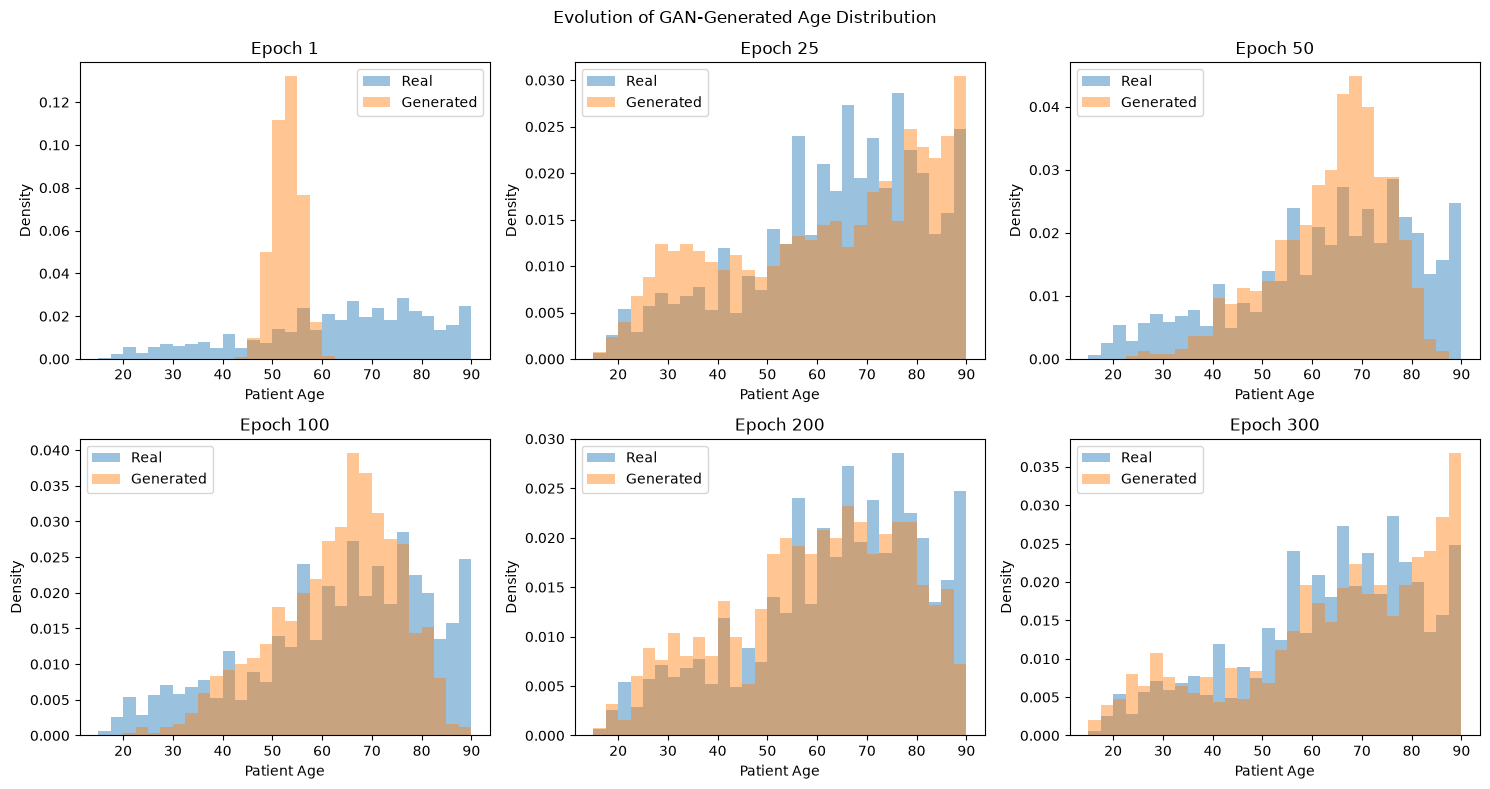

In [137]:
# Visualization of generator improvement
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (epoch, samples) in zip(
    axes.flatten(),
    generated_history.items()
):
    ages_at_epoch = (
        (samples + 1) / 2
    ) * (age_max - age_min) + age_min

    ax.hist(
        valid_ages,
        bins=bins,
        density=True,
        alpha=0.45,
        label="Real"
    )

    ax.hist(
        ages_at_epoch,
        bins=bins,
        density=True,
        alpha=0.45,
        label="Generated"
    )

    ax.set_title(f"Epoch {epoch}")
    ax.set_xlabel("Patient Age")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Evolution of GAN-Generated Age Distribution")
plt.tight_layout()
plt.show()